# PR03 - What surge multiplier should each zone get?

Question: given predicted demand per geohash-6 zone and hour, what surge multiplier should each zone get, and how is it spread across the city?

Demand: PR01 forecast (`pred_count`, test window 2014-09-04 to 2014-09-30), in pickups per cell-hour.
Supply proxy: `trailing_week_mean`, the mean hourly pickups of the same cell over the previous 168 hours. **The datasets contain no driver supply.** This is a demand-history proxy, so read the multiplier as a demand-spike indicator, not a supply-demand balance.
Rule: `m = clip(1 + beta * (D_hat / S - 1), 1, m_max)` with beta = 0.5 and m_max = 3.0. Cells with S < 1 pickups/hour have no usable history and get m = 1.
Map: demand-weighted gaussian smoothing of m, so busy cells dominate the colour.

In [1]:
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pyproj import Transformer

from routes_pricing.plots import add_basemap
from surge_multiplier.surge import demand_weighted_grid, surge_multiplier

DATA_DIR = Path(os.environ.get("UBER_DATA_DIR", "../data")).expanduser()
CACHE = DATA_DIR / "cache"
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

BETA = 0.5
M_MAX = 3.0
MIN_SUPPLY = 1.0

## 1. Load PR01 predictions and compute the multiplier

The cache is written by the PR01 notebook. Only the test window is used, so no model fitting or tuning touches it here.

In [2]:
pred = pd.read_csv(CACHE / "pr01_predictions.csv.gz", parse_dates=["hour"])
test = pred[pred["split"] == "test"].copy()
test["demand"] = test["pred_count"].clip(lower=0)
test["multiplier"] = surge_multiplier(
    test["demand"], test["trailing_week_mean"], beta=BETA, m_max=M_MAX, min_supply=MIN_SUPPLY
)
assert test["multiplier"].between(1.0, M_MAX).all()
print(f"test rows: {len(test):,}  zones: {test.geohash.nunique():,}  hours: {test.hour.nunique():,}")
print(f"window: {test.hour.min()} .. {test.hour.max()}")

test rows: 115,388  zones: 182  hours: 634
window: 2014-09-04 13:00:00 .. 2014-09-30 22:00:00


## 2. Cap and gate checks

The plan requires that the multiplier is capped. Here we check how often the cap binds and how many rows are gated by the supply floor.

In [3]:
diag = pd.Series(
    {
        "share gated (S < 1, m = 1)": (test["trailing_week_mean"] < MIN_SUPPLY).mean(),
        "share with m > 1": (test["multiplier"] > 1).mean(),
        "share at cap (m = m_max)": (test["multiplier"] >= M_MAX - 1e-9).mean(),
        "mean m": test["multiplier"].mean(),
        "max m": test["multiplier"].max(),
    }
)
print(diag.round(4).to_string())

share gated (S < 1, m = 1)    0.5263
share with m > 1              0.1646
share at cap (m = m_max)      0.0001
mean m                        1.0465
max m                         3.0000


## 3. Fairness: multiplier per zone

Averages can hide zones that are surged much more often than others. The table below gives each zone's mean and 90th-percentile multiplier over the test window. The Spearman correlation between zone demand and zone mean multiplier shows whether surge concentrates in low-demand zones.

In [4]:
zone = (
    test.groupby(["geohash", "lat", "lon"])
    .agg(
        mean_demand=("demand", "mean"),
        mean_m=("multiplier", "mean"),
        p90_m=("multiplier", lambda s: s.quantile(0.9)),
        max_m=("multiplier", "max"),
    )
    .reset_index()
)
print(zone[["mean_m", "p90_m", "max_m"]].describe(percentiles=[0.5, 0.9]).round(3).to_string())
print(f"zones with mean m > 1.5: {(zone.mean_m > 1.5).mean():.1%}")
print(f"Spearman corr(zone mean demand, zone mean m): {zone.mean_demand.corr(zone.mean_m, method='spearman'):.3f}")

        mean_m    p90_m    max_m
count  182.000  182.000  182.000
mean     1.046    1.166    1.582
std      0.057    0.212    0.652
min      1.000    1.000    1.000
50%      1.002    1.000    1.257
90%      1.128    1.458    2.557
max      1.193    1.861    3.000
zones with mean m > 1.5: 0.0%


Spearman corr(zone mean demand, zone mean m): 0.924


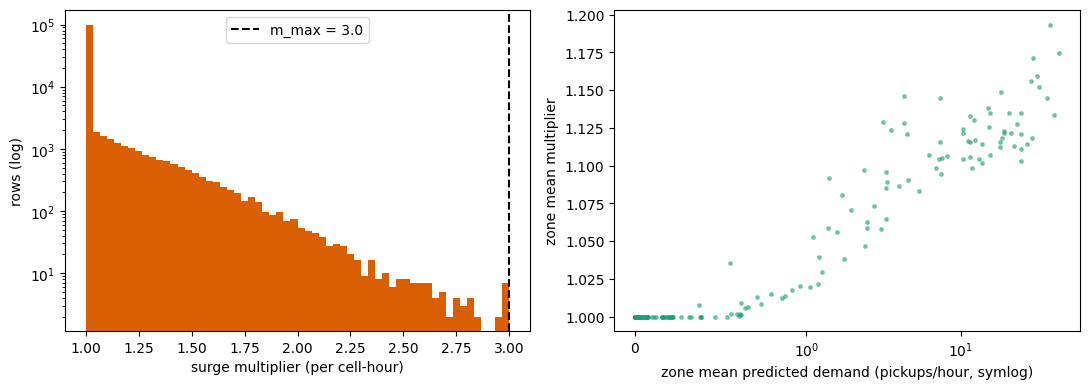

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(test["multiplier"], bins=60, color="#d95f02")
axes[0].axvline(M_MAX, ls="--", color="k", label=f"m_max = {M_MAX}")
axes[0].set_yscale("log")
axes[0].set_xlabel("surge multiplier (per cell-hour)")
axes[0].set_ylabel("rows (log)")
axes[0].legend()
axes[1].scatter(zone.mean_demand, zone.mean_m, s=6, alpha=0.5, color="#1b9e77")
axes[1].set_xscale("symlog", linthresh=1)
axes[1].set_xlabel("zone mean predicted demand (pickups/hour, symlog)")
axes[1].set_ylabel("zone mean multiplier")
fig.tight_layout()
fig.savefig(FIG / "pr03_multiplier_distribution.png", dpi=150)
plt.show()

## 4. Heatmaps on the basemap

Two maps: the demand-weighted average over the whole test window, and the busiest predicted hour (the same hour RT04 uses). Smoothing uses the shared `smoothed_grid` kernel, applied to demand*m and demand, then divided. Blank cells have no predicted demand.

In [6]:
pad = 0.005
bbox = (
    test.lat.min() - pad,
    test.lat.max() + pad,
    test.lon.min() - pad,
    test.lon.max() + pad,
)
to_3857 = Transformer.from_crs("EPSG:4326", "EPSG:3857", always_xy=True)


def plot_surge_map(grid, title, path):
    min_lat, max_lat, min_lon, max_lon = bbox
    lat_edges = np.linspace(min_lat, max_lat, grid.shape[0] + 1)
    lon_edges = np.linspace(min_lon, max_lon, grid.shape[1] + 1)
    lon_mesh, lat_mesh = np.meshgrid(lon_edges, lat_edges)
    x, y = to_3857.transform(lon_mesh, lat_mesh)
    fig, ax = plt.subplots(figsize=(8, 7))
    mesh = ax.pcolormesh(
        x, y, np.ma.masked_invalid(grid), cmap="YlOrRd", vmin=1, vmax=M_MAX, alpha=0.65, shading="flat"
    )
    xmin, ymin = to_3857.transform(min_lon, min_lat)
    xmax, ymax = to_3857.transform(max_lon, max_lat)
    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    add_basemap(ax)
    ax.set_axis_off()
    fig.colorbar(mesh, ax=ax, shrink=0.7, label="surge multiplier")
    ax.set_title(title)
    fig.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()

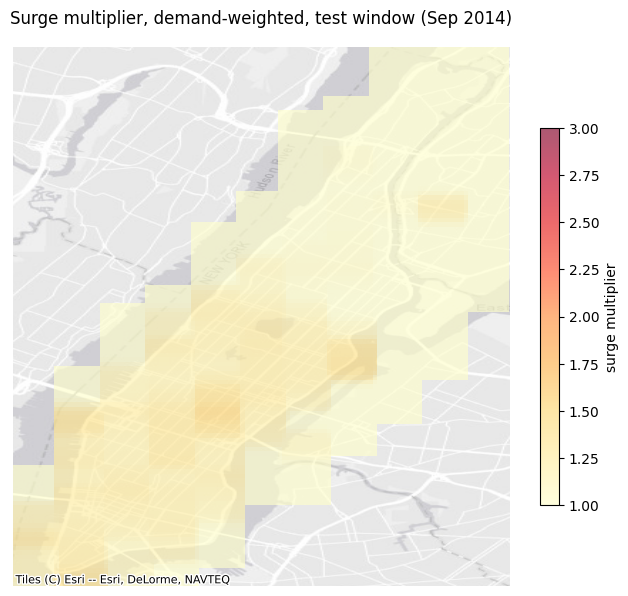

In [7]:
grid_mean, _ = demand_weighted_grid(test.lat, test.lon, test.multiplier, test.demand, bbox)
plot_surge_map(
    grid_mean,
    "Surge multiplier, demand-weighted, test window (Sep 2014)",
    FIG / "pr03_surge_heatmap_mean.png",
)

peak hour: 2014-09-18 18:00:00  predicted pickups: 2,350  zones at cap: 0


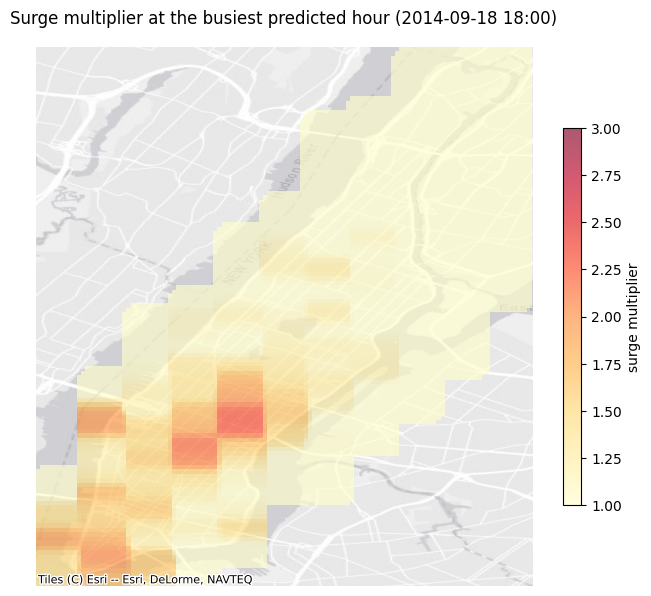

In [8]:
peak_hour = test.groupby("hour")["demand"].sum().idxmax()
peak = test[test["hour"] == peak_hour]
print(f"peak hour: {peak_hour}  predicted pickups: {peak.demand.sum():,.0f}  zones at cap: {(peak.multiplier >= M_MAX - 1e-9).sum()}")
grid_peak, _ = demand_weighted_grid(peak.lat, peak.lon, peak.multiplier, peak.demand, bbox)
plot_surge_map(
    grid_peak,
    f"Surge multiplier at the busiest predicted hour ({peak_hour:%Y-%m-%d %H:%M})",
    FIG / "pr03_surge_heatmap_peak.png",
)